In [47]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import *
import time 

In [48]:
N = 1024 
dx = 0.1 
x = np.arange(-N/2, N/2)*dx 
L = N*dx 

dxi = (2*np.pi)/(N*dx)  
xi = np.arange(-N/2, N/2)*dxi 
W = N*dxi 

In [49]:
a = 2

In [50]:
# Analytical
fa = np.exp((-x**2)/(4*a)) / np.sqrt(4*np.pi*a)
Fa = np.exp(-a*(xi**2))

In [59]:
# Numerical (FFT)
start = time.process_time()
FFTn = fftshift(fft(ifftshift(fa)))*dx 
IFFTn = fftshift(ifft(ifftshift(Fa)))/dx 
end = time.process_time()

print(end - start)

0.001008000000000564


In [60]:
# Numerical (DFT)
start = time.process_time()
DFTn = []
IDFTn = []
for t in range(N):
    DFTn.append(sum(fa*np.exp(-xi[t]*1j*x)*dx))
    IDFTn.append(sum(Fa*np.exp(xi[t]*1j*x)*dxi) / (2*np.pi))
end = time.process_time()

print(end - start)

0.1937850000000001


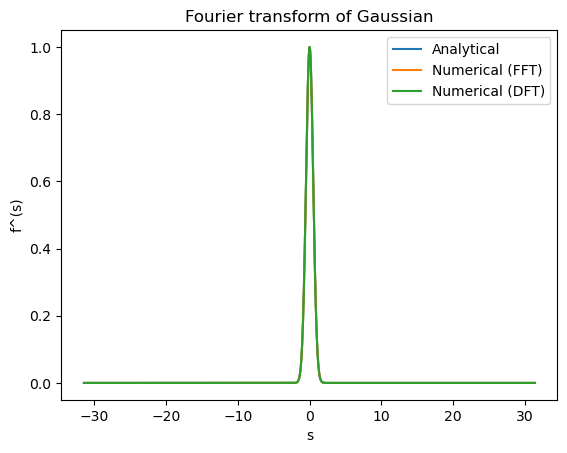

In [55]:
plt.figure(1)
plt.plot(xi, Fa, label='Analytical')
plt.plot(xi, FFTn.real, label='Numerical (FFT)')
plt.plot(xi, np.real(DFTn), label='Numerical (DFT)')
plt.xlabel('s')
plt.ylabel('f^(s)')
plt.title('Fourier transform of Gaussian')
plt.legend()
plt.show()

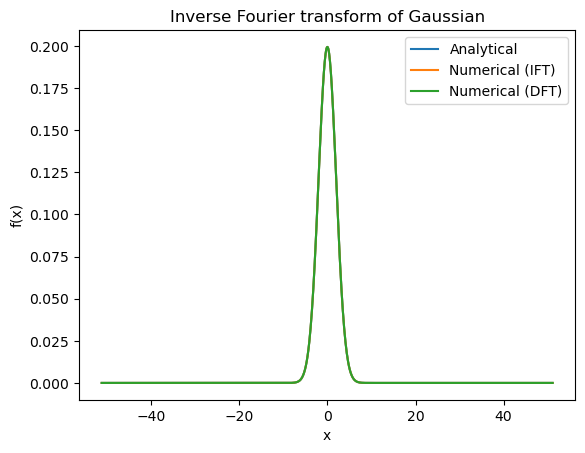

In [56]:
plt.plot(x, fa, label='Analytical')
plt.plot(x, IFFTn.real, label='Numerical (IFT)')
plt.plot(x, np.real(IDFTn), label='Numerical (DFT)')
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title('Inverse Fourier transform of Gaussian')
plt.legend()
plt.show()